In [17]:
import os
import sys

import joblib
import itertools
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import LocalOutlierFactor
from matplotlib.lines import Line2D

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.plotting import plot_movement_data
from utils.constants import Configs
from utils.loso_pipeline import run_loso_evaluation
from utils.loso_models.lof_detector import LOFDetector
from utils.helper_functions import calculate_matrix_trash_percentage
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.dtw_radius import load_dtw_matrices

TARGET_MOVEMENT = 'Move'
ALGORITHM_NAME = 'LOF'
MODEL_REPRESENTATION = 'ShapeBased'

EXTRACT_SCORES = True

In [18]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [19]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID', 'movID'])
total_known_outliers = len(outliers_csv)

# Filter the outliers for the target movement
outliers_csv = outliers_csv[outliers_csv['movLabel'] == TARGET_MOVEMENT].reset_index(drop=True)
total_target_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
print(f"Total target outliers: {total_target_outliers}")
outliers_csv.head()

Total known outliers: 18
Total target outliers: 5


,sub,repID,movID,movLabel
0,2,2,9,Move
1,4,1,9,Move
2,7,1,9,Move
3,11,1,9,Move
4,12,1,9,Move


In [20]:
# Making sure that the metadata is perfectly aligned with the movement data matrix (X_movement)
df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

group_array = ['x', 'y', 'z']
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series: 100%|██████████| 95/95 [00:00<00:00, 2232.16it/s]

Shape of first series: (72, 3)
Shape of formatted series: (95, 196, 3)


In [21]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================

results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().reset_index(drop=True)

total_samples = len(results_temp_base)                                  
total_trials  = len(df_filtered[['sub', 'repID']].drop_duplicates())
known_outlier_rate = (total_target_outliers / total_samples) if total_samples > 0 else 0.0
percentagem_conhecida = known_outlier_rate * 100


if total_samples != X_movement.shape[0]:
    raise ValueError(f"⚠️ ERROR: Metadata ({total_samples}) does not match the matrix ({X_movement.shape[0]})!")

print(f"✅ Perfect Synchronization! Rows in Matrix: {X_movement.shape[0]} | Rows in Metadata: {total_samples}")
print(f"Total samples in the matrix: {total_samples}")
print(f"Total unique repetitions analyzed ({TARGET_MOVEMENT}): {total_trials}")
print(f"Minimum confirmed outlier rate from the CSV (Sub + RepID + movID): {percentagem_conhecida:.2f}%")

✅ Perfect Synchronization! Rows in Matrix: 95 | Rows in Metadata: 95
Total samples in the matrix: 95
Total unique repetitions analyzed (Move): 95
Minimum confirmed outlier rate from the CSV (Sub + RepID + movID): 5.26%


## Local Outlier Factor (LOC)

### Grid Search

In [22]:
n_neighbors_options = [3, 5, 7, 10, 15, 20]

param_grid = [
    {'n_neighbors': n, 'contamination': c} 
    for n, c in itertools.product(n_neighbors_options, Configs.CONTAMINATION_GRID)
]

matrices = load_dtw_matrices(TARGET_MOVEMENT, Configs.DTW_RADIUS_Seconds, Configs.wrist_only_constrained_dtw_distance_matrix)

loso_results = run_loso_evaluation(
    detector_class=LOFDetector, 
    param_grid=param_grid,
    data_matrix=matrices[0.5], # placeholder, replaced per fold
    metadata_df=results_temp_base,
    known_outliers_df=outliers_csv,
    metric_type='precomputed',
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    dtw_matrices=matrices
)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)

print("\nSearch Results:")
print("Teste", f"MCC={loso_results['MCC']:.3f}", f"Rej={loso_results['Rejection_Rate']:.1f}%",
          f"AUROC={loso_results['AUROC']:.3f}")

LOSO Cross-Validation with 19 subjects (5 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 
Search Results:
Teste MCC=0.286 Rej=15.8% AUROC=0.916


### Statistic Evaluation (TRIAL-LEVEL) - Bootstraping

In [23]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [24]:
append_experiment_record(
    summary_path=Configs.WRIST_ONLY_CSV_SHAPE_BASED_SUMMARY_FILE,
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=total_samples,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for LOF - ShapeBased - Move - 95 Movements (MOVEMENT-level):
Unique Outliers Detected: 15
Rejection Rate: 15.79%
Known Positives in Ground Truth: 5
------------------------------
Total True Positives (Global):  3
Total False Positives (Global): 12
Total False Negatives (Global): 2
Total True Negatives (Global):  78
------------------------------
Blind Precision: 20.00 [0.00–66.67]
Blind Recall:    60.00 [0.00–100.00]
Blind F1-Score:  30.00
Blind F2-Score:  42.86 [0.00–76.19]
Blind MCC:       0.29 [-0.05–0.69]
Blind AUPRC:  46.90 [12.78–100.00]
Blind AUROC:   91.56

Total Tuning Time (19 Subjects): 11.2340s
Total Inference Time (19 Subjects): 0.0222s

Overall Best Parameters (Most frequent across folds):
   {'contamination': 0.06, 'n_neighbors': 5}
Occurrences: 11


### Train Model

I should only trust the loso metrics, the metrics shown below suffers from data leakage, so the metrics are way much higher.

I'm training this final model because I need a **clean** dataset for me to train my future GMM's with the inliers from this model

In [25]:
best_params = loso_results['Best_Params']
best_n_neighbors = best_params['n_neighbors']
best_contamination = best_params['contamination']

selected_radius = loso_results['Most_Frequent_DTW_Radius']
selected_dtw_matrix = matrices[selected_radius]      # `matrices` is the dict loaded earlier

In [26]:
lof_model = LocalOutlierFactor(n_neighbors=best_n_neighbors, contamination=best_contamination, n_jobs=-1, metric='precomputed')
labels = lof_model.fit_predict(selected_dtw_matrix)
joblib.dump(lof_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

outlier_indices = np.where(labels == -1)[0]
n_outliers = len(outlier_indices)

In [27]:
# Reconstruct metadata for cross-referencing with the original CSV
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

n_unique_outliers, correct_trash_pct = calculate_matrix_trash_percentage(outlier_indices, metadata_df)

X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
X_movement_outliers = X_movement[outlier_indices]

print(f"Raw Outlier Trials Detected: {n_outliers}")
print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
print(f"Detected Trash Percentage (sub + repID + movID): {(n_outliers/len(selected_dtw_matrix)*100):.2f}%") # instead of total_trials, I can use len(dtw_matrix)
print(f"Detected Trash Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected: 6
Unique Outlier Trials Detected: 6
Detected Trash Percentage (sub + repID + movID): 6.32%
Detected Trash Percentage (sub + repID): 6.32%


In [28]:
real_outliers_info = metadata_df.iloc[outlier_indices][["sub", "repID", "movID", "movLabel"]]
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

print("Outlier Details:")
print(real_outliers_info)

Outlier Details:
    sub  repID  movID movLabel
6     2      2      9     Move
15    4      1      9     Move
24    5      5      9     Move
30    7      1      9     Move
50   11      1      9     Move
55   12      1      9     Move


In [29]:
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = show_feature_extraction_metrics(
    metadata_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 5
False Positives (Identified, not in CSV): 1
False Negatives (In CSV, not identified): 0
True Negatives (Normal, stayed normal): 89
--------------------------------------------------
Missing outliers (In CSV, not identified):
Empty DataFrame
Columns: [sub, repID]
Index: []

Precision (False Positives): 5/6 (83.33%)
Recall (True Positive Rate): 5/5 (100.00%)
F1-Score: 90.91%
F2-Score: 96.15%


### Plot Things

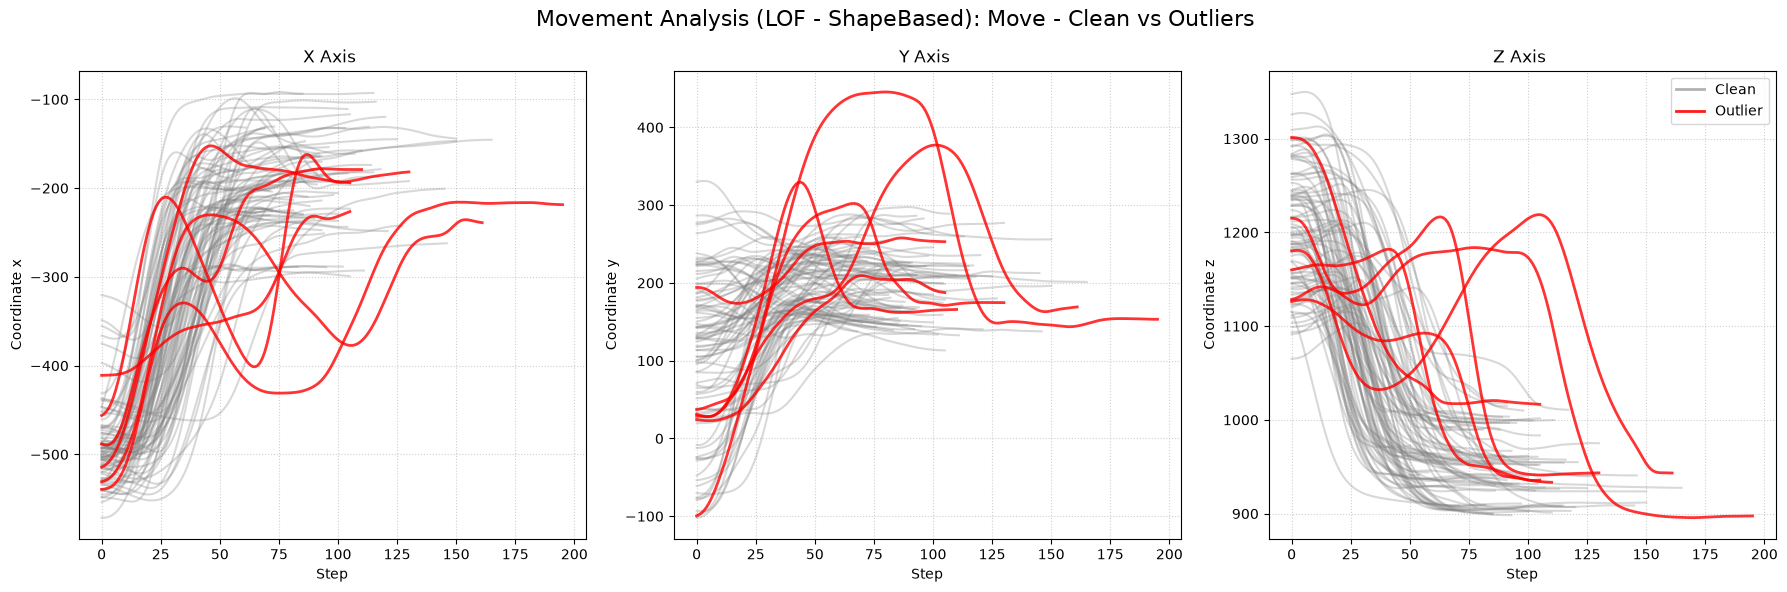

In [30]:
plot_movement_data(
    clean_data=X_movement_clean,
    outlier_data=X_movement_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)

[Move] common=5 | model_only=1 | csv_only=0


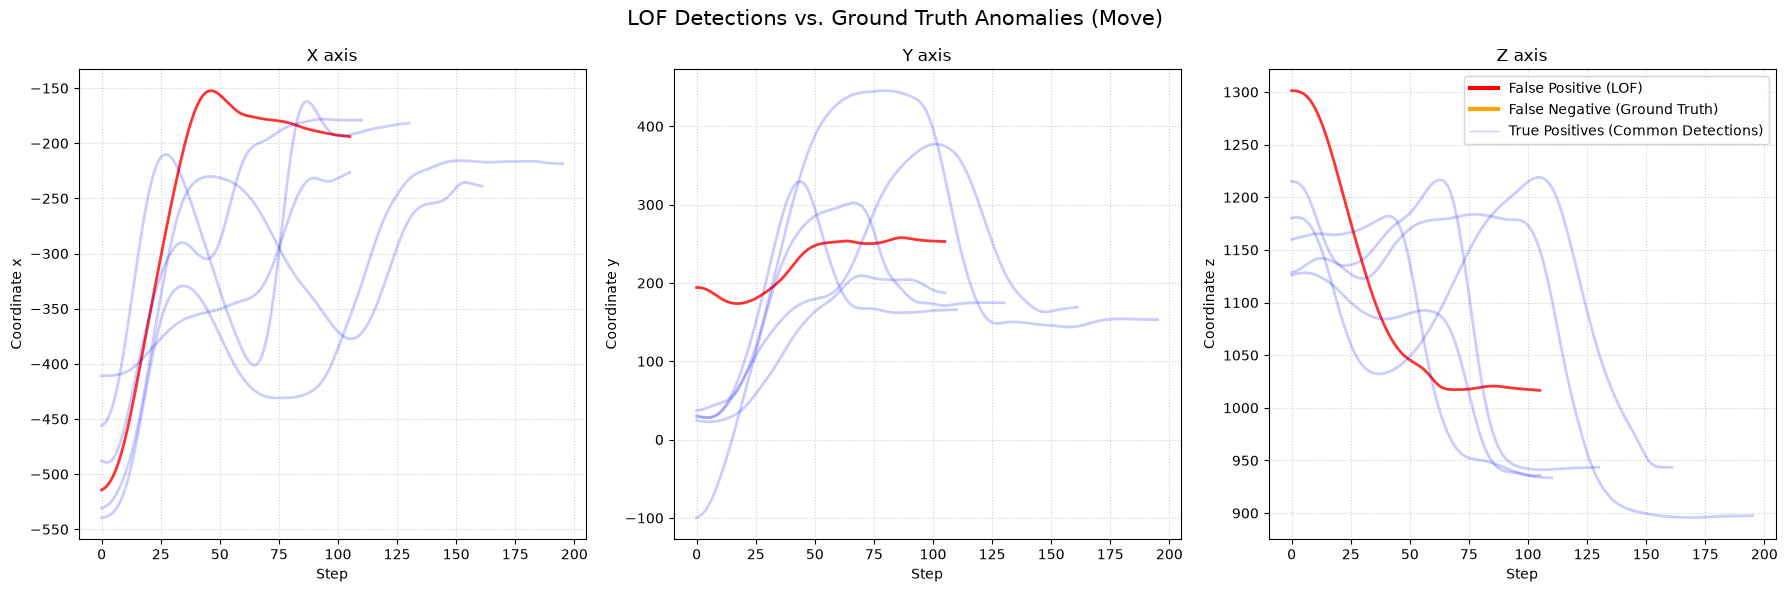

In [31]:
def plot_model_vs_csv_from_lof_output(
    X_movement,
    metadata_df,          # mesma ordem de X_movement
    outlier_indices,      # np.where(labels == -1)[0]
    outliers_csv,         # colunas: sub, repID
    axis_names=('x', 'y', 'z'),
    target_movement='Place'
):
    # Chaves únicas
    model_keys = metadata_df.iloc[outlier_indices][['sub', 'repID']].drop_duplicates()
    csv_keys = outliers_csv[['sub', 'repID']].drop_duplicates()

    # Interseções/diferenças
    common_keys = model_keys.merge(csv_keys, on=['sub', 'repID'], how='inner')

    model_only_keys = model_keys.merge(
        csv_keys, on=['sub', 'repID'], how='left', indicator=True
    )
    model_only_keys = model_only_keys[model_only_keys['_merge'] == 'left_only'][['sub', 'repID']]

    csv_only_keys = csv_keys.merge(
        model_keys, on=['sub', 'repID'], how='left', indicator=True
    )
    csv_only_keys = csv_only_keys[csv_only_keys['_merge'] == 'left_only'][['sub', 'repID']]

    # Mapear para índices em X_movement (usando metadata completo)
    full_pairs = metadata_df[['sub', 'repID']].apply(tuple, axis=1)

    common_idx = np.where(full_pairs.isin(common_keys.apply(tuple, axis=1)))[0]
    model_only_idx = np.where(full_pairs.isin(model_only_keys.apply(tuple, axis=1)))[0]
    csv_only_idx = np.where(full_pairs.isin(csv_only_keys.apply(tuple, axis=1)))[0]

    X_common = X_movement[common_idx] if len(common_idx) else np.empty((0,))
    X_model_only = X_movement[model_only_idx] if len(model_only_idx) else np.empty((0,))
    X_csv_only = X_movement[csv_only_idx] if len(csv_only_idx) else np.empty((0,))

    print(f"[{target_movement}] common={len(common_idx)} | model_only={len(model_only_idx)} | csv_only={len(csv_only_idx)}")

    # Plot
    fig, axs = plt.subplots(1, len(axis_names), figsize=(18, 6))
    if len(axis_names) == 1:
        axs = [axs]

    legend_elements = [
        Line2D([0], [0], color='red', lw=3, alpha=1.0, label=f'False Positive (LOF)'),
        Line2D([0], [0], color='orange', lw=3, alpha=1.0, label='False Negative (Ground Truth)'),
        Line2D([0], [0], color='blue', lw=1, alpha=0.2, label='True Positives (Common Detections)'),
    ]

    for i, axis in enumerate(axis_names):
        ax = axs[i]

        for series in X_model_only:
            ax.plot(series[:, i], color='red', alpha=0.8, linewidth=2)

        for series in X_csv_only:
            ax.plot(series[:, i], color='orange', alpha=0.8, linewidth=2)

        for series in X_common:
            ax.plot(series[:, i], color='blue', alpha=0.2, linewidth=2)

        ax.set_title(f'{axis.upper()} axis')
        ax.set_xlabel('Step')
        ax.set_ylabel(f'Coordinate {axis}')
        ax.grid(True, linestyle=':', alpha=0.6)

        if i == len(axis_names) - 1:
            ax.legend(handles=legend_elements, loc='upper right')

    plt.suptitle(f'LOF Detections vs. Ground Truth Anomalies ({target_movement})', fontsize=15)
    plt.tight_layout()
    plt.show()

plot_model_vs_csv_from_lof_output(
    X_movement=X_movement,
    metadata_df=metadata_df,          
    outlier_indices=outlier_indices,  
    outliers_csv=outliers_csv,
    axis_names=group_array,
    target_movement=TARGET_MOVEMENT
)


In [32]:
# # =========================================================================
# # LIMPEZA E EXPORTAÇÃO DO DATASET DE INLIERS
# # =========================================================================

# df_target_only = df[df['movLabel'] == TARGET_MOVEMENT].copy()
# outliers_keys = real_outliers_info[['sub', 'repID', 'movID', 'movLabel']].copy()

# df_cleaned = pd.merge(df_target_only, outliers_keys, on=['sub', 'repID', 'movID', 'movLabel'], how='left', indicator=True)
# df_cleaned = df_cleaned[df_cleaned['_merge'] == 'left_only'].drop(columns=['_merge'])

# print(f"\n--- RESUMO DA LIMPEZA ({TARGET_MOVEMENT}) ---")
# print(f"Linhas do movimento antes da limpeza: {len(df_target_only)}")
# print(f"Linhas removidas (outliers): {len(df_target_only) - len(df_cleaned)}")
# print(f"Linhas limpas: {len(df_cleaned)}")

# # Para confirmar os movimentos únicos que sobraram do TARGET_MOVEMENT
# movimentos_restantes = df_cleaned[['sub', 'repID', 'movID']].drop_duplicates()
# print(f"\nMovimentos '{TARGET_MOVEMENT}' que SOBRARAM: {len(movimentos_restantes)}")
# print(f"Movimentos originais eram {total_trials}, removemos {n_outliers}, batem certo? {len(movimentos_restantes) == (total_trials - n_outliers)}\n")

# save_path = Configs.cached_wrist_only_dtw_inliers('LOF', TARGET_MOVEMENT) 
# joblib.dump(df_cleaned, save_path)
# print(f"✅ Dataset de Inliers limpo guardado em: {save_path}")